# Solutions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Polynomial fitting with SVD

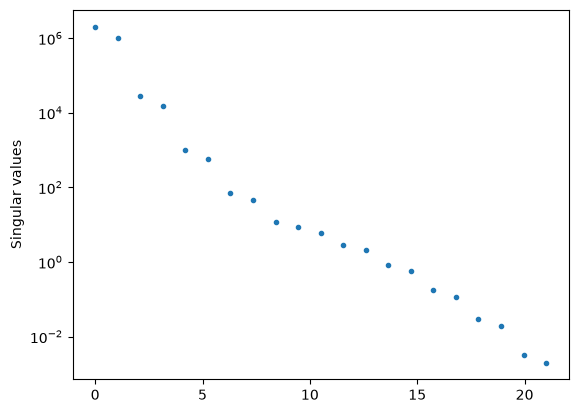

Range of singular values = 1.02088e+09
np.linalg.cond gives 1.02088e+09
Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0      0.160097      0.160097   4.24528e-11
x^1       0.80283       0.80283   2.49315e-11
x^2      0.745007      0.745007   2.86164e-11
x^3     -0.785998     -0.785998   5.67756e-10
x^4     -0.986277     -0.986277   9.09198e-10
x^5      0.929968      0.929968   1.09178e-09
x^6     -0.682748     -0.682748  -4.18583e-09
x^7     -0.911465     -0.911465   2.25059e-09
x^8         0.661         0.661   -1.1691e-08
x^9     -0.939843     -0.939843  -3.71219e-09
x^10      0.692917      0.692917   6.92694e-09
x^11     -0.747187     -0.747187   2.90565e-09
x^12      0.291534      0.291534  -1.28594e-08
x^13      0.263357      0.263357   3.09935e-10
x^14     -0.352479     -0.352479  -6.22369e-09
x^15      0.692052      0.692052   1.29511e-11
x^16     -0.441151     -0.441151   8.99843e-10
x^17     -0.904048     -0.904048   7.93694e-12
x^18      0.730777     

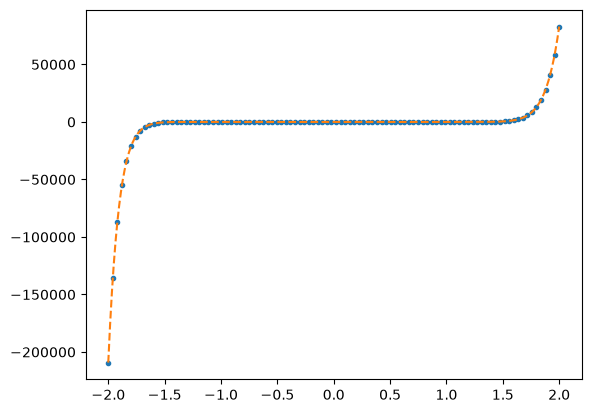

In [2]:
# first generate some data from a random polynomial

k = 20 # order of polynomial
n = 100  # number of data points
sigma = 0 # noise
useSVD = True

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk
# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

# plot the singular values
plt.clf()
plt.plot(np.linspace(0,len(Sdiag),len(Sdiag)),Sdiag,'.')
plt.yscale('log')
plt.ylabel(r'Singular values')
plt.show()
    
print("Range of singular values = %g" % (max(abs(Sdiag))/min(abs(Sdiag))))
print("np.linalg.cond gives %g" % (np.linalg.cond(A)))

# Now do the linear algebra part
if useSVD:
    a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
else:
    rhs = np.transpose(A)@y
    lhs = np.transpose(A)@A
    a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
plt.figure()
plt.plot(x,y,'.')
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()

## Orthogonal polynomials

In [3]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

In [4]:
# first generate some data from a random polynomial
k = 20  # order of polynomial
n = 100   # number of data points

kfit = 20  # number of basis functions for the fit

x = np.linspace(-2,2,n)
a0 = -1.0 + 2*np.random.rand(k+1)
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=0.0, size=n)

# OR try a more complicated function
#y = np.exp(np.sin(x**3)) + np.tanh(x)**3

In [5]:
def do_fit(A, y, use_svd = True):
    
    if use_svd:
        U, Sdiag, VT = np.linalg.svd(A,0)
        a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
    else:
        rhs = np.transpose(A)@y
        lhs = np.transpose(A)@A
        a = np.linalg.inv(lhs)@rhs

    return a

<Figure size 640x480 with 0 Axes>

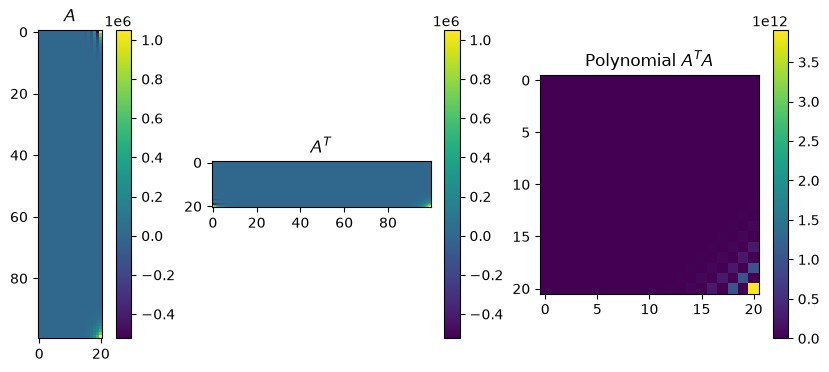

Condition number = 1.02088e+09


<Figure size 640x480 with 0 Axes>

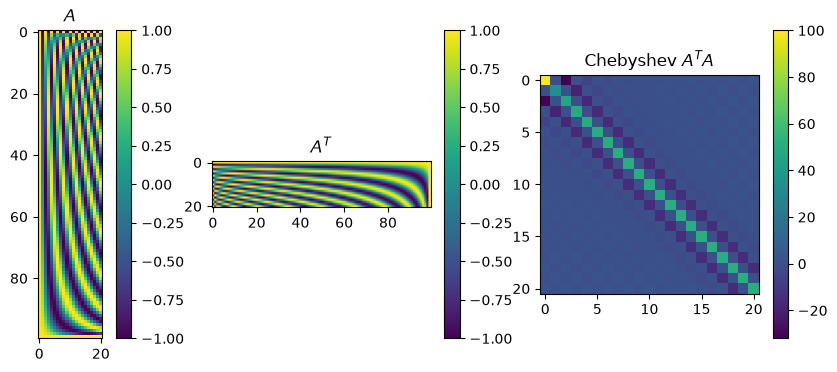

Condition number = 3.1319
Chebyshev coefficients:
a0 92053.4
a1 170946
a2 167802
a3 139774
a4 126824
a5 93049
a6 79047.8
a7 49980.4
a8 40226.5
a9 21339
a10 16450.3
a11 7073.55
a12 5276.5
a13 1754.52
a14 1278.7
a15 306.251
a16 220.207
a17 33.5164
a18 24.0404
a19 1.72719
a20 1.2532
mean square deviation = 3.01639e-20


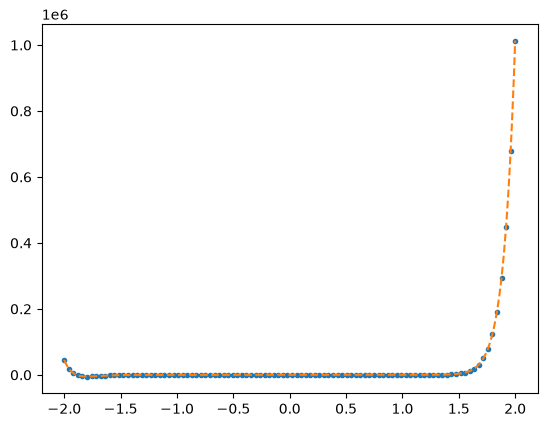

In [6]:
# As a comparison, compute the design matrix as if we were using regular polynomials
A = np.vander(x, N=kfit+1, increasing=True)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Polynomial $A^TA$"])
print("Condition number = %g" % (np.linalg.cond(A)))

# Fit with Chebyshev polynomials
A = np.polynomial.chebyshev.chebvander(x/2,kfit)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Chebyshev $A^TA$"])
print("Condition number = %g" % (np.linalg.cond(A)))

a_cheb = do_fit(A, y)
      
print("Chebyshev coefficients:")
for i in range(len(a_cheb)):
    print("a%d %g" % (i, a_cheb[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_cheb = np.polynomial.Chebyshev(a_cheb)
yy = poly_cheb(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_cheb(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

Condition number = 6.42377


<Figure size 640x480 with 0 Axes>

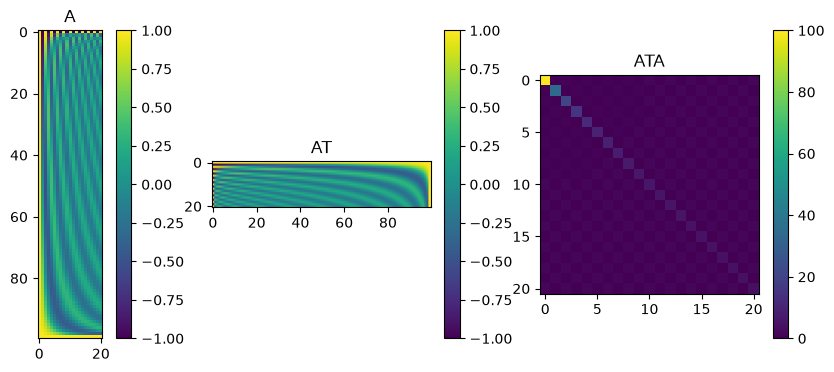

Legendre coefficients:
a0 24556.8
a1 69407
a2 107188
a3 126656
a4 140178
a5 127193
a6 121699
a7 89711.8
a8 78307.9
a9 46841
a10 38338
a11 18188
a12 14215.6
a13 5134.68
a14 3886.97
a15 999.407
a16 741.977
a17 120.108
a18 88.587
a19 6.71612
a20 4.99796
mean square deviation = 7.60064e-19


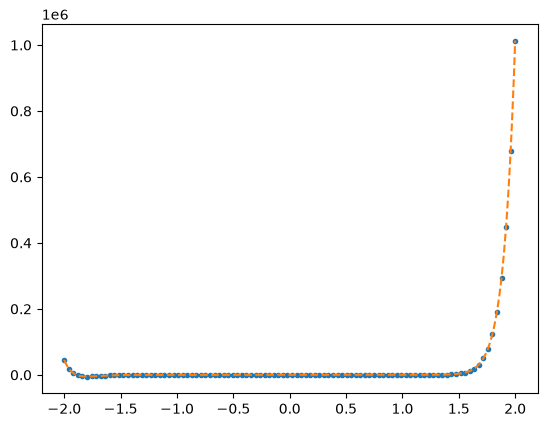

In [7]:
# Fit with Legendre polynomials
A = np.polynomial.legendre.legvander(x/2,kfit)

print("Condition number = %g" % (np.linalg.cond(A)))
plot_matrices([A,A.T,A.T@A], titles=["A","AT","ATA"])

a_leg = do_fit(A, y)
      
print("Legendre coefficients:")
for i in range(len(a_leg)):
    print("a%d %g" % (i, a_leg[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_leg = np.polynomial.Legendre(a_leg)
yy = poly_leg(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_leg(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()